# Evaluator: Visibility Extent and Top-\(k\) Breakthrough Discovery

This notebook evaluates the outputs of `Visibility_extent_top_k_list(1).py`. All dependent variables concern the **receiver crowd**; sender solutions provide exposure opportunities.

The new experiment reports **average breakthrough ranks for each of the top 1–10 final receiver solutions**, rather than only the highest-ranked solution. Set `selected_top_k` to reproduce the original rank figures for any desired \(k\). A supplementary comparison plots all top-\(k\) measures together. The existing diversity, adoption, fitness, trajectory, and by-\(K\) figures are retained.

**Input:** Pickle outputs written by the new simulation, including a separate `_top_{k}` file for every breakthrough-rank measure. No simulation rerun is required. The notebook saves **PNG figures only** (no CSV files).

## 1. Configuration and methods

- The settings below match the **actual assignments** in `Visibility_extent_top_k_list(1).py`: `N=18`, `K=[2,4,6,8,10]`, `agent_num=100` in each crowd, `knowledge_breadth=12`, `search_iteration=300`, and `visibility_interval=10`.
- The script uses 400 landscape repetitions and 5 independent solver resets per landscape; saved values are already averaged over these runs **for each (extent, K)**. Overall plots then average equally over the five configured K values.
- **Note:** The script's comment says `K=9,...,17`, but its actual `K_list` is `[2, 4, 6, 8, 10]`. This notebook follows the executable list. Change both configurations if you intended the other range.
- Top-\(k\) breakthrough rank is the mean of the \(k\) *best-ranked final receiver-solver solutions* within each run (not necessarily \(k\) distinct configurations). **Lower ranks indicate better discoveries.** `selected_top_k=1` reproduces the original best-solution-rank measure.
- Saved results contain only run averages, not repetition-level variation. The notebook therefore cannot recover confidence intervals or conduct significance tests.
- `adopted_solution_fitness` is the mean true fitness of adopted solutions, conditional on adoption; it is undefined (`NaN`) when no adoption occurs. Its time trajectory is a cumulative mean.

**Edit `result_folder` to your new pickle output directory.** Figures are saved under its `visibility_extent_figures` subfolder.

In [1]:
from pathlib import Path
import pickle
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

# Matched to the earlier evaluator notebook.
legend_properties = {'weight': 'bold'}
nus_blue = '#003D7C'
nus_orange = '#EF7C00'
morandi_blue = '#046586'
morandi_green = '#28A9A1'
morandi_yellow = '#C9A77C'
morandi_orange = '#F4A016'
morandi_pink = '#F6BBC6'
morandi_red = '#E71F19'
morandi_purple = '#B08BEB'
shallow_grey = '#D3D4D3'

K_colors = [morandi_blue, morandi_orange, morandi_green, morandi_purple,
            morandi_red, morandi_yellow, '#555555', '#B75F91']


def safe_nanmean(values, axis=None):
    """Ignore structurally undefined adoption values, retaining all-NaN as NaN."""
    with warnings.catch_warnings():
        warnings.simplefilter('ignore', category=RuntimeWarning)
        return np.nanmean(values, axis=axis)


In [2]:
# =========================
# Experiment configuration — active values in Visibility_extent_top_k_list(1).py
# =========================
N = 18
K_list = [2, 4, 6, 8, 10]  # Actual script setting; its K=9,...,17 comment is outdated.
agent_num = 100
knowledge_breadth = 12
landscape_iteration = 400  # Documentation only; results were averaged upstream.
solver_reset_num = 5       # Documentation only; results were averaged upstream.
search_iteration = 300
visibility_interval = 10
visibility_extent_list = [0.0, 0.01, 0.02, 0.04, 0.08,
                          0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0]

top_k_list = list(range(1, 11))  # Load the script's top-1 through top-10 outputs.
selected_top_k = 1           # Rank figures / rank heatmap: change to any k above.
comparison_top_k_list = top_k_list  # k values in the overlay comparison figure.
export_all_top_k_rank_figures = True  # Save one rank-vs-extent PNG per k.

if selected_top_k not in top_k_list:
    raise ValueError('selected_top_k must be in top_k_list.')
if not comparison_top_k_list or any(k not in top_k_list for k in comparison_top_k_list):
    raise ValueError('comparison_top_k_list must contain k values in top_k_list.')

rank_axis_label = ('Best solution rank (lower is better)' if selected_top_k == 1
                   else f'Top-{selected_top_k} average solution rank (lower is better)')

# Change to the folder containing your new pickle outputs; use None to auto-detect.
result_folder = "/Volumes/T7/data/gst-1010-26/ISR_Visibility_5/Extent_top_k"
strict_loading = True  # False permits unfinished sets of output files.

candidate_folders = [Path.cwd(), Path.cwd() / 'Results', Path.cwd() / 'results',
                     Path.cwd() / 'output', Path.cwd() / 'data']
expected_example = (f'visibility_extent_{visibility_extent_list[0]}_interval_{visibility_interval}'
                    f'_breakthrough_rank_across_K_size_{agent_num}_top_{selected_top_k}')
if result_folder is None:
    result_folder = next((folder for folder in candidate_folders
                          if (folder / expected_example).is_file()), Path.cwd())
result_folder = Path(result_folder).expanduser()
figure_folder = result_folder / 'visibility_extent_figures'
figure_folder.mkdir(parents=True, exist_ok=True)

print('Result folder:', result_folder)
print('Output folder:', figure_folder)
print('Example expected file:', expected_example)
print('Selected breakthrough rank: top-', selected_top_k, sep='')
print('Folder exists:', result_folder.exists())

Result folder: /Volumes/T7/data/gst-1010-26/ISR_Visibility_5/Extent_top_k
Output folder: /Volumes/T7/data/gst-1010-26/ISR_Visibility_5/Extent_top_k/visibility_extent_figures
Example expected file: visibility_extent_0.0_interval_10_breakthrough_rank_across_K_size_100_top_1
Selected breakthrough rank: top-1
Folder exists: True


## 2. Load and validate the output families

The new simulation saves the breakthrough rank separately for each \(k\):

`visibility_extent_{extent}_interval_{interval}_breakthrough_rank_across_K_size_{agent_num}_top_{k}`

The other **four scalar outcome families** retain the original unsuffixed filenames, as does the adoption-fitness time trajectory:

`visibility_extent_{extent}_interval_{interval}_{DV}_across_K_size_{agent_num}`

All scalar arrays have shape `(extent, K)`; adoption trajectories have shape `(extent, K, visibility event)`. The loader creates `data['breakthrough_rank_by_k'][k]` for every \(k\), with `data['breakthrough_rank']` as a convenience alias for `selected_top_k`. It checks file shapes and retains undefined or unavailable observations as `NaN`.

In [3]:
other_scalar_dvs = [
    'breakthrough_fitness',
    'pairwise_diversity',
    'unique_solution_count',
    'adopted_solution_fitness',
]
scalar_dvs = ['breakthrough_rank'] + other_scalar_dvs
trajectory_dv = 'adopted_solution_fitness_across_time'
expected_events = search_iteration // visibility_interval


def result_file(extent, dv, top_k=None):
    filename = (f'visibility_extent_{extent}_interval_{visibility_interval}_'
                f'{dv}_across_K_size_{agent_num}')
    if dv == 'breakthrough_rank':
        if top_k is None:
            raise ValueError('Specify top_k when loading a breakthrough-rank file.')
        filename += f'_top_{top_k}'
    elif top_k is not None:
        raise ValueError('Only breakthrough-rank filenames have a top_k suffix.')
    return result_folder / filename


def load_pickle(path):
    with open(path, 'rb') as infile:
        return pickle.load(infile)


def load_visibility_extent_results(strict=True):
    n_extent = len(visibility_extent_list)
    n_K = len(K_list)
    rank_by_k = {k: np.full((n_extent, n_K), np.nan) for k in top_k_list}
    data = {dv: np.full((n_extent, n_K), np.nan) for dv in other_scalar_dvs}
    data[trajectory_dv] = np.full((n_extent, n_K, expected_events), np.nan)
    data['breakthrough_rank_by_k'] = rank_by_k
    data['breakthrough_rank'] = rank_by_k[selected_top_k]

    missing_files = []
    invalid_files = []
    per_extent_outputs = [(dv, None) for dv in other_scalar_dvs + [trajectory_dv]]
    per_extent_outputs += [('breakthrough_rank', k) for k in top_k_list]

    for i, extent in enumerate(visibility_extent_list):
        for dv, k in per_extent_outputs:
            path = result_file(extent, dv, top_k=k)
            if not path.is_file():
                missing_files.append(path.name)
                continue
            try:
                values = np.asarray(load_pickle(path), dtype=float)
            except (OSError, EOFError, pickle.UnpicklingError, TypeError, ValueError) as exc:
                invalid_files.append((path.name, str(exc)))
                continue
            shape = (n_K, expected_events) if dv == trajectory_dv else (n_K,)
            if values.shape != shape:
                invalid_files.append((path.name, f'got {values.shape}; expected {shape}'))
                continue
            if dv == 'breakthrough_rank':
                rank_by_k[k][i] = values
            else:
                data[dv][i] = values

    total_files = n_extent * len(per_extent_outputs)
    print(f'Files loaded: {total_files - len(missing_files) - len(invalid_files)} / {total_files}')
    print('Scalar shapes:', {dv: data[dv].shape for dv in scalar_dvs})
    print('Trajectory shape:', data[trajectory_dv].shape)
    print('Top-k rank keys:', list(rank_by_k))

    if missing_files:
        print(f'\nMissing files ({len(missing_files)}):')
        for filename in missing_files[:12]:
            print('  ', filename)
        if len(missing_files) > 12:
            print('  ...')
    if invalid_files:
        print(f'\nInvalid files ({len(invalid_files)}):')
        for name, issue in invalid_files[:12]:
            print('  ', name, ':', issue)

    if strict and (missing_files or invalid_files):
        raise FileNotFoundError(
            'Missing/invalid results. Check result_folder, top_k_list, K_list, '
            'agent_num, visibility_interval, and visibility_extent_list, or set '
            'strict_loading=False for unfinished runs. First expected file: '
            + str(result_file(visibility_extent_list[0], 'breakthrough_rank', selected_top_k))
        )
    if not any(np.isfinite(data[dv]).any() for dv in scalar_dvs):
        raise FileNotFoundError('No valid scalar pickle outputs found in ' + str(result_folder))
    return data


data = load_visibility_extent_results(strict=strict_loading)

Files loaded: 225 / 225
Scalar shapes: {'breakthrough_rank': (15, 5), 'breakthrough_fitness': (15, 5), 'pairwise_diversity': (15, 5), 'unique_solution_count': (15, 5), 'adopted_solution_fitness': (15, 5)}
Trajectory shape: (15, 5, 30)
Top-k rank keys: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10]


In [4]:
# =========================
# Data checks and long-form details
# =========================
checks = {
    'breakthrough_rank': (1, 2 ** N),
    'breakthrough_fitness': (0, 1),
    'pairwise_diversity': (0, 1),
    'unique_solution_count': (1, agent_num),
    'adopted_solution_fitness': (0, 1),
}
for dv, (minimum, maximum) in checks.items():
    finite = data[dv][np.isfinite(data[dv])]
    outside = np.count_nonzero((finite < minimum - 1e-8) | (finite > maximum + 1e-8))
    print(f'{dv:29s} finite={finite.size:3d} / {data[dv].size:3d}; outside expected range={outside}')

# For each (extent, K), adding the next-best-ranked receiver solution cannot
# improve (decrease) the average rank; verify this across every successive k.
rank_stack = np.stack([data['breakthrough_rank_by_k'][k] for k in top_k_list], axis=-1)
nonmonotonic = np.count_nonzero(np.diff(rank_stack, axis=-1) < -1e-8)
print(f'Top-k rank monotonicity violations: {nonmonotonic}')
if nonmonotonic:
    warnings.warn('Top-k rank means are unexpectedly nonmonotonic. Check the input files.')

for k in top_k_list:
    ranks = data['breakthrough_rank_by_k'][k]
    finite = ranks[np.isfinite(ranks)]
    outside = np.count_nonzero((finite < 1 - 1e-8) | (finite > 2 ** N + 1e-8))
    print(f'top-{k:2d} rank: finite={finite.size:3d} / {ranks.size:3d}; outside range={outside}')

# The final cumulative trajectory should equal the scalar adoption measure.
last_trajectory = data[trajectory_dv][:, :, -1]
both_defined = np.isfinite(last_trajectory) & np.isfinite(data['adopted_solution_fitness'])
if both_defined.any():
    gap = np.max(np.abs(last_trajectory[both_defined] - data['adopted_solution_fitness'][both_defined]))
    print('Max discrepancy: final trajectory vs. scalar adoption quality =', round(float(gap), 12))

rows = []
for i, extent in enumerate(visibility_extent_list):
    for j, K in enumerate(K_list):
        row = {'visibility_extent': extent, 'K': K}
        for dv in scalar_dvs:
            row[dv] = data[dv][i, j]
        for k in top_k_list:
            row[f'breakthrough_rank_top_{k}'] = data['breakthrough_rank_by_k'][k][i, j]
        rows.append(row)

detailed_results = pd.DataFrame(rows)
print('\nDetailed data preview (one observation per extent × K):')
display(detailed_results.head(12).round(4))

breakthrough_rank             finite= 75 /  75; outside expected range=0
breakthrough_fitness          finite= 75 /  75; outside expected range=0
pairwise_diversity            finite= 75 /  75; outside expected range=0
unique_solution_count         finite= 75 /  75; outside expected range=0
adopted_solution_fitness      finite= 70 /  75; outside expected range=0
Top-k rank monotonicity violations: 0
top- 1 rank: finite= 75 /  75; outside range=0
top- 2 rank: finite= 75 /  75; outside range=0
top- 3 rank: finite= 75 /  75; outside range=0
top- 4 rank: finite= 75 /  75; outside range=0
top- 5 rank: finite= 75 /  75; outside range=0
top- 6 rank: finite= 75 /  75; outside range=0
top- 7 rank: finite= 75 /  75; outside range=0
top- 8 rank: finite= 75 /  75; outside range=0
top- 9 rank: finite= 75 /  75; outside range=0
top-10 rank: finite= 75 /  75; outside range=0
Max discrepancy: final trajectory vs. scalar adoption quality = 0.0

Detailed data preview (one observation per extent × K):


,visibility_extent,K,breakthrough_rank,breakthrough_fitness,pairwise_diversity,unique_solution_count,adopted_solution_fitness,breakthrough_rank_top_1,breakthrough_rank_top_2,breakthrough_rank_top_3,breakthrough_rank_top_4,breakthrough_rank_top_5,breakthrough_rank_top_6,breakthrough_rank_top_7,breakthrough_rank_top_8,breakthrough_rank_top_9,breakthrough_rank_top_10
0,0.00,2,9.3255,0.9761,0.4582,98.7885,NaN,9.3255,15.6560,23.3208,31.8120,41.1891,51.6064,62.9386,75.1889,88.2948,102.5193
1,0.00,4,11.6470,0.9617,0.4923,99.3150,NaN,11.6470,19.9972,29.3945,39.7698,51.2732,63.9528,77.4751,92.0136,107.5685,124.1395
2,0.00,6,16.9020,0.9482,0.4984,99.5190,NaN,16.9020,27.2882,39.0113,52.0445,66.4676,82.1466,98.8588,116.7235,135.6319,155.7926
3,0.00,8,23.0410,0.9384,0.4996,99.6405,NaN,23.0410,37.5752,53.5783,71.1842,90.3118,110.7369,132.3639,155.4626,180.1103,205.8354
4,0.00,10,37.1565,0.9234,0.4999,99.7375,NaN,37.1565,58.1818,81.6652,106.7385,133.9035,163.0203,193.8209,226.1814,259.5755,294.6350
5,0.01,2,9.5800,0.9768,0.3767,79.1365,0.7189,9.5800,15.4175,21.5007,28.2119,35.5065,43.0680,51.1136,59.7240,68.8443,78.3318
6,0.01,4,12.2405,0.9624,0.4031,77.7145,0.7124,12.2405,20.1118,28.2425,37.0689,46.5208,56.8462,67.8068,79.4905,91.6697,104.4485
7,0.01,6,19.4515,0.9472,0.4033,74.8885,0.7074,19.4515,31.2432,43.5173,56.4175,69.7559,84.3033,99.5881,115.4346,131.8902,148.7764
8,0.01,8,29.8305,0.9321,0.4042,73.1455,0.7006,29.8305,47.0850,64.9812,83.7156,103.2176,123.5040,144.5213,166.2844,188.7866,211.9562
9,0.01,10,46.6845,0.9222,0.4005,70.7745,0.6977,46.6845,71.9992,98.4513,126.6835,156.0613,187.4920,219.5333,252.6406,286.2897,321.1917


## 3. Main results: visibility extent

The overall curves average each outcome equally across **all actual K values** in `K_list`. The by-K figures show variation across landscape complexity. **Rank figures use `selected_top_k`; the default top-1 reproduces the original dependent variable.** Lines join the sampled extents at their actual numerical positions.

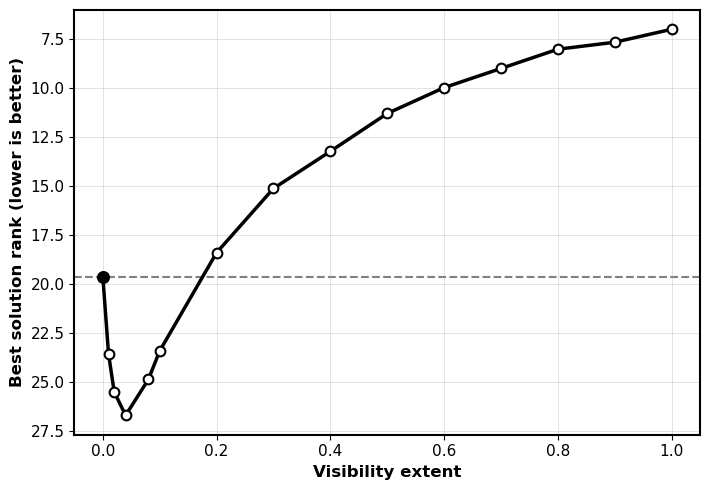

In [5]:
# Top-k average solution rank across visibility extent (average across K).
fig, ax = plt.subplots(figsize=(7.2, 5.0))

for spine in ax.spines.values():
    spine.set_linewidth(1.5)
    spine.set_color('black')

ax.grid(alpha=0.5)
ax.tick_params(axis='both', labelsize=11)

x = np.asarray(visibility_extent_list)
y_rank = safe_nanmean(data['breakthrough_rank'], axis=1)

# Main curve
ax.plot(
    x, y_rank,
    marker='o',
    linewidth=2.5,
    markersize=7,
    color='k',
    markerfacecolor='white',
    markeredgecolor='black',
    markeredgewidth=1.5,
    zorder=2
)

# -------------------------
# Horizontal benchmark line:
# performance under parallel search (visibility extent = 0)
# -------------------------
zero_idx = np.where(np.isclose(x, 0.0))[0][0]
baseline_rank = y_rank[zero_idx]

ax.axhline(
    y=baseline_rank,
    color='gray',
    linestyle='--',
    linewidth=1.5,
    zorder=1
)

# Optional: highlight the baseline point itself
ax.scatter(
    x[zero_idx],
    baseline_rank,
    s=70,
    color='black',
    zorder=3
)

ax.invert_yaxis()  # Rank 1 is best; invert so a better rank is visually higher.
ax.set_xlabel('Visibility extent', fontweight='bold', fontsize=12)
ax.set_ylabel(rank_axis_label, fontweight='bold', fontsize=12)

fig.tight_layout()

plt.savefig(
    figure_folder / ('Breakthrough_across_visibility_extent.png' if selected_top_k == 1
                     else f'Breakthrough_across_visibility_extent_top_{selected_top_k}.png'),
    dpi=300,
    bbox_inches='tight',
    transparent=True
)

plt.show()

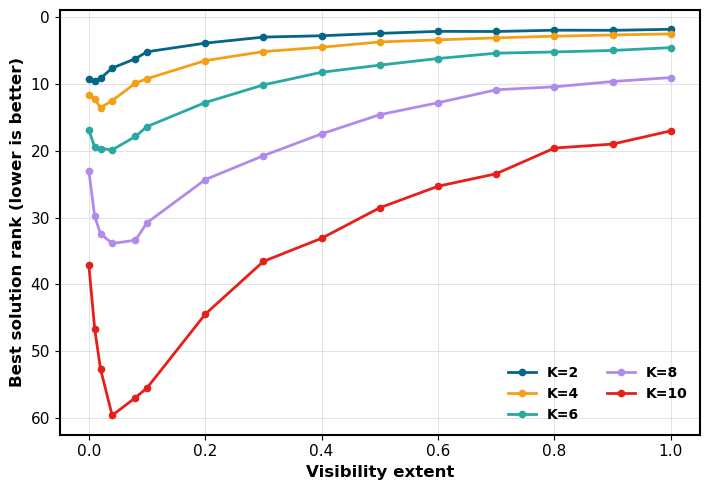

In [6]:
# Selected top-k solution rank across visibility extent (by K).
fig, ax = plt.subplots(figsize=(7.2, 5.0))
for spine in ax.spines.values():
    spine.set_linewidth(1.5)
    spine.set_color('black')
ax.grid(alpha=0.5)
ax.tick_params(axis='both', labelsize=11)
for j, K in enumerate(K_list):
    ax.plot(visibility_extent_list, data['breakthrough_rank'][:, j],
            marker='o', linewidth=2.0, markersize=4.5,
            label=f'K={K}', color=K_colors[j % len(K_colors)])
ax.invert_yaxis()
ax.set_xlabel('Visibility extent', fontweight='bold', fontsize=12)
ax.set_ylabel(rank_axis_label, fontweight='bold', fontsize=12)
ax.legend(frameon=False, ncol=2, prop={'weight': 'bold', 'size': 10})
fig.tight_layout()
plt.savefig(figure_folder / ('Breakthrough_by_K_across_visibility_extent.png' if selected_top_k == 1
                             else f'Breakthrough_by_K_across_visibility_extent_top_{selected_top_k}.png'), dpi=300, bbox_inches='tight', transparent=True)
plt.show()

### Top-\(k\) robustness: compare all breakthrough-rank measures

Each colored curve averages equally over the configured \(K\) values for a different \(k\). Higher \(k\) incorporates additional, lower-ranked final receiver solutions, so the mean rank is weakly increasing in \(k\) at each extent and \(K\). **Compare the shape of the visibility effect within a curve**, not the absolute level across different \(k\).

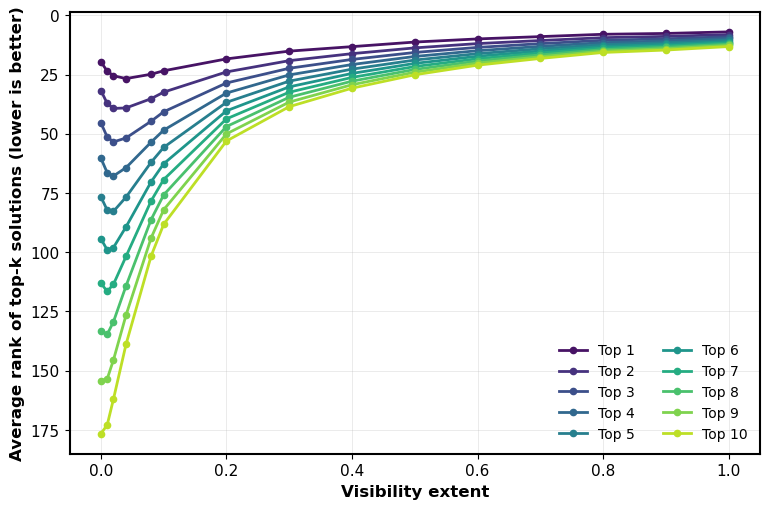

In [7]:
# Compare top-k breakthrough ranks across visibility extent (average across K).
x = np.asarray(visibility_extent_list)
fig, ax = plt.subplots(figsize=(7.8, 5.2))
for spine in ax.spines.values():
    spine.set_linewidth(1.5)
    spine.set_color('black')
ax.grid(alpha=0.35)
ax.tick_params(axis='both', labelsize=11)

colors = plt.cm.viridis(np.linspace(0.05, 0.9, len(comparison_top_k_list)))
for color, k in zip(colors, comparison_top_k_list):
    y_top_k = safe_nanmean(data['breakthrough_rank_by_k'][k], axis=1)
    ax.plot(x, y_top_k, marker='o', linewidth=2.0, markersize=4.5,
            color=color, label=f'Top {k}')

ax.invert_yaxis()  # Better (lower) rank appears higher.
ax.set_xlabel('Visibility extent', fontweight='bold', fontsize=12)
ax.set_ylabel('Average rank of top-k solutions (lower is better)', fontweight='bold', fontsize=12)
ax.legend(frameon=False, ncol=2, prop={'size': 10})
fig.tight_layout()
plt.savefig(figure_folder / 'Breakthrough_rank_top_k_comparison_across_visibility_extent.png',
            dpi=300, bbox_inches='tight', transparent=True)
plt.show()

### Export individual top-\(k\) figures

When `export_all_top_k_rank_figures=True`, this cell saves a separate rank-versus-extent PNG for **every** \(k\) while keeping the original figure style and search-apart benchmark. The figures are closed after saving to avoid cluttering the notebook.

In [8]:
if export_all_top_k_rank_figures:
    for k in top_k_list:
        x = np.asarray(visibility_extent_list)
        y_rank_k = safe_nanmean(data['breakthrough_rank_by_k'][k], axis=1)
        fig, ax = plt.subplots(figsize=(7.2, 5.0))
        for spine in ax.spines.values():
            spine.set_linewidth(1.5)
            spine.set_color('black')
        ax.grid(alpha=0.5)
        ax.tick_params(axis='both', labelsize=11)
        ax.plot(x, y_rank_k, marker='o', linewidth=2.5, markersize=7, color='k',
                markerfacecolor='white', markeredgecolor='black', markeredgewidth=1.5, zorder=2)

        zero_idx = np.where(np.isclose(x, 0.0))[0][0]
        if np.isfinite(y_rank_k[zero_idx]):
            ax.axhline(y=y_rank_k[zero_idx], color='gray', linestyle='--', linewidth=1.5, zorder=1)
            ax.scatter(x[zero_idx], y_rank_k[zero_idx], s=70, color='black', zorder=3)
        ax.invert_yaxis()
        ax.set_xlabel('Visibility extent', fontweight='bold', fontsize=12)
        ax.set_ylabel('Best solution rank (lower is better)' if k == 1 else
                      f'Top-{k} average solution rank (lower is better)',
                      fontweight='bold', fontsize=12)
        fig.tight_layout()
        fig.savefig(figure_folder / f'Breakthrough_across_visibility_extent_top_{k}.png',
                    dpi=300, bbox_inches='tight', transparent=True)
        plt.close(fig)
    print(f'Saved {len(top_k_list)} individual top-k breakthrough-rank PNG files to {figure_folder}')

Saved 10 individual top-k breakthrough-rank PNG files to /Volumes/T7/data/gst-1010-26/ISR_Visibility_5/Extent_top_k/visibility_extent_figures


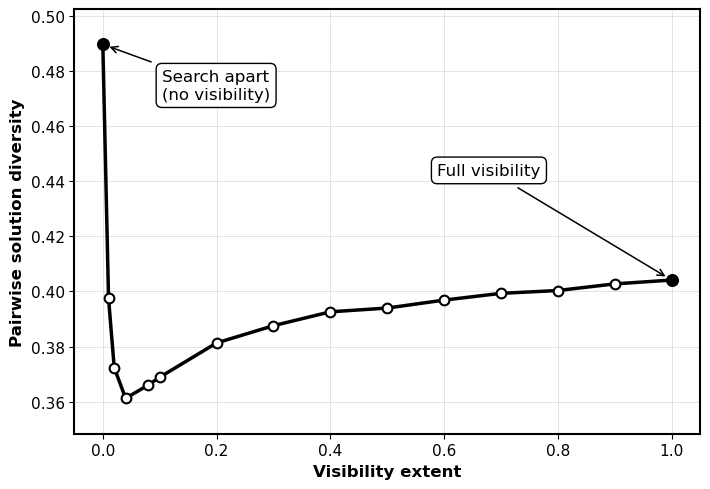

Saved: /Volumes/T7/data/gst-1010-26/ISR_Visibility_5/Extent_top_k/visibility_extent_figures/Pairwise_diversity_across_visibility_extent.png


In [9]:
# =========================
# Pairwise diversity across visibility extent (average across K)
# =========================
fig, ax = plt.subplots(figsize=(7.2, 5.0))

# -------------------------
# Axis formatting
# -------------------------
for spine in ax.spines.values():
    spine.set_linewidth(1.5)
    spine.set_color("black")

ax.grid(alpha=0.5)
ax.tick_params(axis="both", labelsize=11)

# -------------------------
# Data
# -------------------------
x = np.asarray(visibility_extent_list)
y = safe_nanmean(data["pairwise_diversity"], axis=1)

# Identify zero-visibility and full-visibility benchmark points
zero_idx = np.where(np.isclose(x, 0.0))[0][0]
full_idx = np.where(np.isclose(x, 1.0))[0][0]

zero_x, zero_y = x[zero_idx], y[zero_idx]
full_x, full_y = x[full_idx], y[full_idx]

# -------------------------
# Main curve
# -------------------------
ax.plot(
    x,
    y,
    marker="o",
    linewidth=2.5,
    markersize=7,
    color="k",
    markerfacecolor="white",
    markeredgecolor="black",
    markeredgewidth=1.5,
    zorder=2,
)

# Give endpoint observations some breathing room
ax.set_xlim(-0.05, 1.05)
ax.margins(y=0.10)

# Highlight the two focal observations
ax.scatter(
    zero_x,
    zero_y,
    s=70,
    color="black",
    zorder=3,
)

ax.scatter(
    full_x,
    full_y,
    s=70,
    color="black",
    zorder=3,
)

# -------------------------
# Annotation-box style
# -------------------------
textbox_style = dict(
    boxstyle="round,pad=0.35",
    facecolor="white",
    edgecolor="black",
    linewidth=1.0,
)

arrow_style = dict(
    arrowstyle="->",
    linewidth=1.1,
    color="black",
    shrinkA=5,
    shrinkB=5,
)

# -------------------------
# Zero visibility annotation
# -------------------------
ax.annotate(
    "Search apart\n(no visibility)",
    xy=(zero_x, zero_y),
    xycoords="data",
    xytext=(0.14, 0.82),
    textcoords="axes fraction",
    ha="left",
    va="center",
    fontsize=12,
    bbox=textbox_style,
    arrowprops=arrow_style,
    annotation_clip=True,
    zorder=4,
)

# -------------------------
# Full visibility annotation
# -------------------------
ax.annotate(
    "Full visibility",
    xy=(full_x, full_y),
    xycoords="data",
    xytext=(0.58, 0.62),
    textcoords="axes fraction",
    ha="left",
    va="center",
    fontsize=12,
    bbox=textbox_style,
    arrowprops=arrow_style,
    annotation_clip=True,
    zorder=4,
)

# -------------------------
# Axes
# -------------------------
ax.set_xlabel(
    "Visibility extent",
    fontweight="bold",
    fontsize=12,
)

ax.set_ylabel(
    "Pairwise solution diversity",
    fontweight="bold",
    fontsize=12,
)

plt.tight_layout()

output_png = figure_folder / "Pairwise_diversity_across_visibility_extent.png"

plt.savefig(
    output_png,
    dpi=300,
    bbox_inches="tight",
    transparent=True,
)

plt.show()

print("Saved:", output_png)

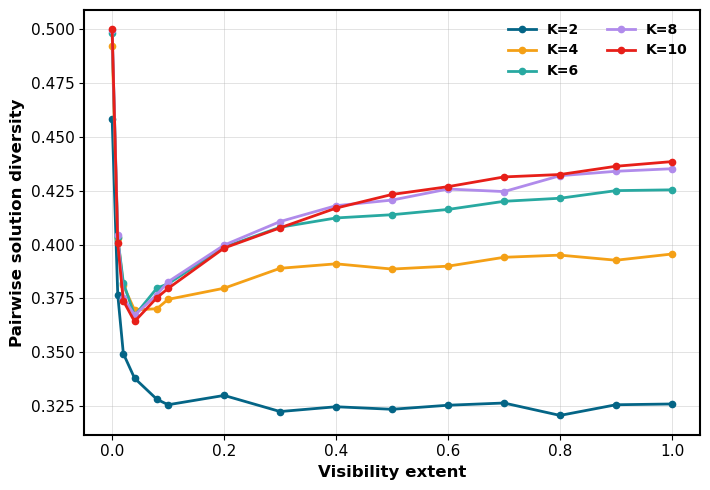

In [10]:
# Pairwise diversity across visibility extent (by K).
fig, ax = plt.subplots(figsize=(7.2, 5.0))
for spine in ax.spines.values():
    spine.set_linewidth(1.5)
    spine.set_color('black')
ax.grid(alpha=0.5)
ax.tick_params(axis='both', labelsize=11)
for j, K in enumerate(K_list):
    ax.plot(visibility_extent_list, data['pairwise_diversity'][:, j],
            marker='o', linewidth=2.0, markersize=4.5,
            label=f'K={K}', color=K_colors[j % len(K_colors)])
ax.set_xlabel('Visibility extent', fontweight='bold', fontsize=12)
ax.set_ylabel('Pairwise solution diversity', fontweight='bold', fontsize=12)
ax.legend(frameon=False, ncol=2, prop={'weight': 'bold', 'size': 10})
fig.tight_layout()
plt.savefig(figure_folder / 'Pairwise_diversity_by_K_across_visibility_extent.png', dpi=300, bbox_inches='tight', transparent=True)
plt.show()

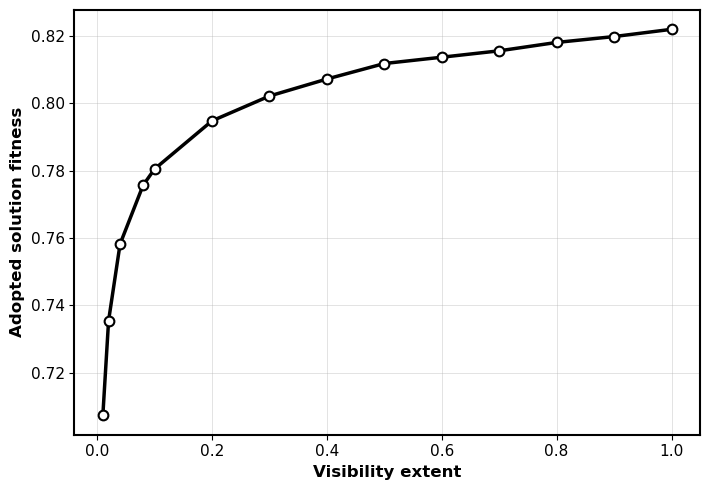

In [11]:
# Adopted solution fitness across visibility extent (average across K).
# Undefined outcomes (including v=0) stay NaN and are not shown as zero.
fig, ax = plt.subplots(figsize=(7.2, 5.0))
for spine in ax.spines.values():
    spine.set_linewidth(1.5)
    spine.set_color('black')
ax.grid(alpha=0.5)
ax.tick_params(axis='both', labelsize=11)
y_adopted = safe_nanmean(data['adopted_solution_fitness'], axis=1)
ax.plot(np.asarray(visibility_extent_list), y_adopted, marker='o', linewidth=2.5, markersize=7, color='k',
        markerfacecolor='white', markeredgecolor='black', markeredgewidth=1.5)
ax.set_xlabel('Visibility extent', fontweight='bold', fontsize=12)
ax.set_ylabel('Adopted solution fitness', fontweight='bold', fontsize=12)
fig.tight_layout()
plt.savefig(figure_folder / 'Adopted_solution_quality_across_visibility_extent.png', dpi=300, bbox_inches='tight', transparent=True)
plt.show()

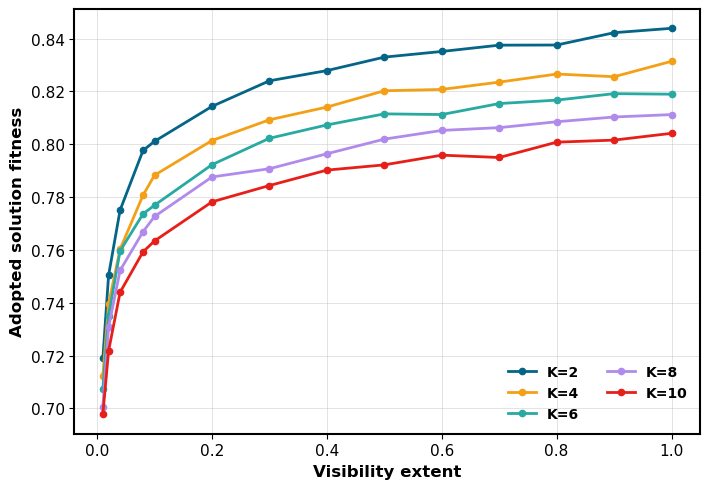

In [12]:
# Adopted solution fitness across visibility extent (by K).
fig, ax = plt.subplots(figsize=(7.2, 5.0))
for spine in ax.spines.values():
    spine.set_linewidth(1.5)
    spine.set_color('black')
ax.grid(alpha=0.5)
ax.tick_params(axis='both', labelsize=11)
for j, K in enumerate(K_list):
    ax.plot(visibility_extent_list, data['adopted_solution_fitness'][:, j],
            marker='o', linewidth=2.0, markersize=4.5,
            label=f'K={K}', color=K_colors[j % len(K_colors)])
ax.set_xlabel('Visibility extent', fontweight='bold', fontsize=12)
ax.set_ylabel('Adopted solution fitness', fontweight='bold', fontsize=12)
ax.legend(frameon=False, ncol=2, prop={'weight': 'bold', 'size': 10})
fig.tight_layout()
plt.savefig(figure_folder / 'Adopted_solution_fitness_by_K_across_visibility_extent.png', dpi=300, bbox_inches='tight', transparent=True)
plt.show()

## 4. Additional outcomes

`breakthrough_fitness` measures the highest final receiver-solution fitness in each run; `breakthrough_rank_by_k[k]` measures the average landscape rank of the top \(k\) final receiver-solver solutions. These use different scales and top-\(k\) aggregation currently applies **only to the rank measure**. `unique_solution_count` captures the number of distinct final receiver configurations, whereas pairwise diversity captures how different those configurations are.

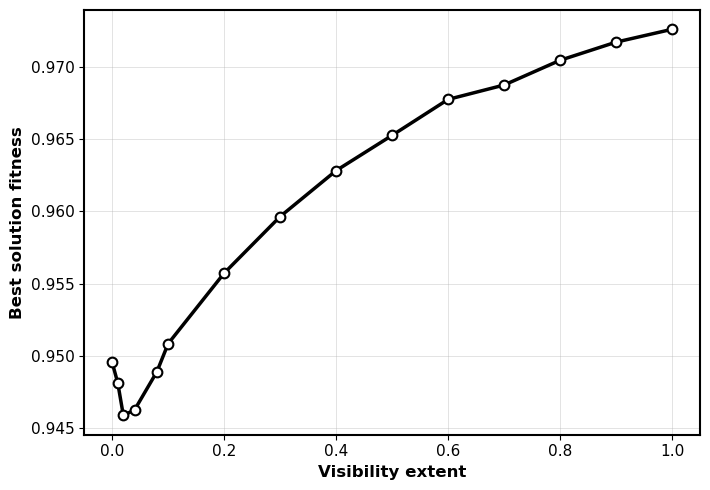

In [13]:
# Best solution fitness across visibility extent (average across K).
fig, ax = plt.subplots(figsize=(7.2, 5.0))
for spine in ax.spines.values():
    spine.set_linewidth(1.5)
    spine.set_color('black')
ax.grid(alpha=0.5)
ax.tick_params(axis='both', labelsize=11)
y_fitness = safe_nanmean(data['breakthrough_fitness'], axis=1)
ax.plot(np.asarray(visibility_extent_list), y_fitness, marker='o', linewidth=2.5, markersize=7, color='k',
        markerfacecolor='white', markeredgecolor='black', markeredgewidth=1.5)
ax.set_xlabel('Visibility extent', fontweight='bold', fontsize=12)
ax.set_ylabel('Best solution fitness', fontweight='bold', fontsize=12)
fig.tight_layout()
# plt.savefig(figure_folder / 'Best_solution_fitness_across_visibility_extent.png', dpi=300, bbox_inches='tight', transparent=True)
plt.show()

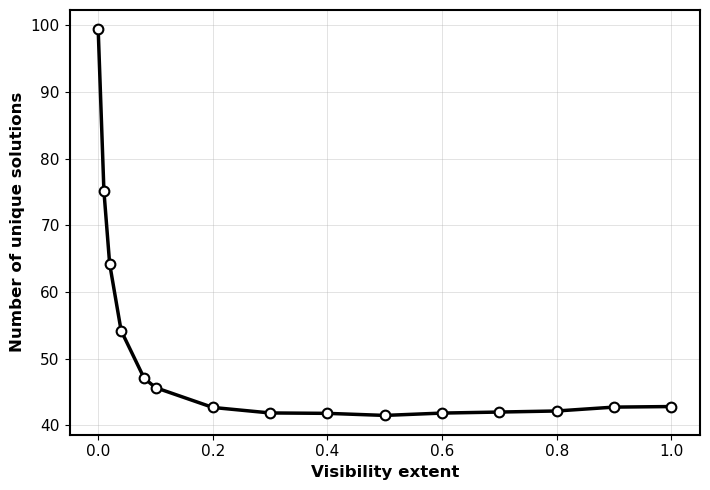

In [14]:
# Unique solution count across visibility extent (average across K).
fig, ax = plt.subplots(figsize=(7.2, 5.0))
for spine in ax.spines.values():
    spine.set_linewidth(1.5)
    spine.set_color('black')
ax.grid(alpha=0.5)
ax.tick_params(axis='both', labelsize=11)
y_unique = safe_nanmean(data['unique_solution_count'], axis=1)
ax.plot(np.asarray(visibility_extent_list), y_unique, marker='o', linewidth=2.5, markersize=7, color='k',
        markerfacecolor='white', markeredgecolor='black', markeredgewidth=1.5)
ax.set_xlabel('Visibility extent', fontweight='bold', fontsize=12)
ax.set_ylabel('Number of unique solutions', fontweight='bold', fontsize=12)
fig.tight_layout()
# plt.savefig(figure_folder / 'Unique_solution_count_across_visibility_extent.png', dpi=300, bbox_inches='tight', transparent=True)
plt.show()

## 5. Adoption-quality trajectories across search time

Set `trajectory_visibility_extent` to any sampled visibility extent. The horizontal axis gives actual search periods (`10, 20, ..., 300` by default). Values are **cumulative mean fitness of adopted solutions through that event**, not fitness of only that period's adoptions or mean fitness of all receiver solutions. The first figure averages all K values; the second plots every K separately.

In [15]:
trajectory_visibility_extent = 1.0  # Change to any entry in visibility_extent_list.
if trajectory_visibility_extent not in visibility_extent_list:
    raise ValueError('trajectory_visibility_extent must appear in visibility_extent_list.')
trajectory_index = visibility_extent_list.index(trajectory_visibility_extent)
trajectory_periods = (np.arange(1, expected_events + 1) * visibility_interval)
trajectory_by_K = data[trajectory_dv][trajectory_index]  # (K, visibility event)
print('Trajectory extent:', trajectory_visibility_extent)
print('Visibility events:', len(trajectory_periods), '| last search period:', trajectory_periods[-1])
print('Defined trajectory entries:', np.isfinite(trajectory_by_K).sum(), '/', trajectory_by_K.size)

Trajectory extent: 1.0
Visibility events: 30 | last search period: 300
Defined trajectory entries: 150 / 150


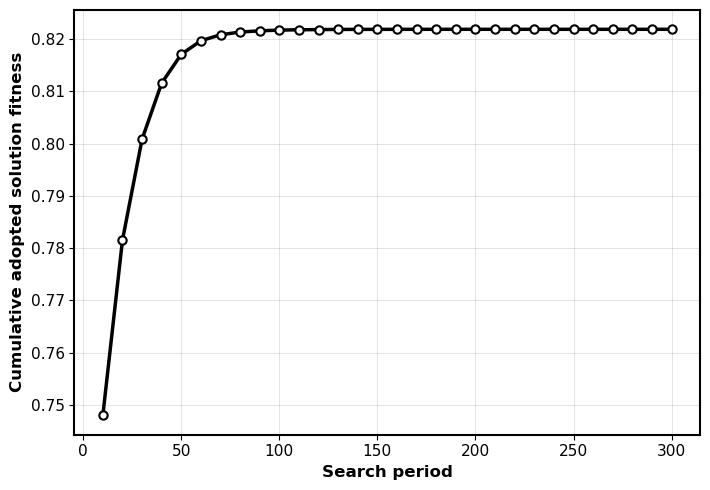

In [16]:
# Cumulative adopted solution fitness across search periods (average across K).
fig, ax = plt.subplots(figsize=(7.2, 5.0))
for spine in ax.spines.values():
    spine.set_linewidth(1.5)
    spine.set_color('black')
ax.grid(alpha=0.5)
ax.tick_params(axis='both', labelsize=11)
trajectory_mean = safe_nanmean(trajectory_by_K, axis=0)
ax.plot(trajectory_periods, trajectory_mean, marker='o', linewidth=2.5,
        markersize=6, color='k', markerfacecolor='white', markeredgecolor='black', markeredgewidth=1.5)
ax.set_xlabel('Search period', fontweight='bold', fontsize=12)
ax.set_ylabel('Cumulative adopted solution fitness', fontweight='bold', fontsize=12)
fig.tight_layout()
# plt.savefig(figure_folder / f'Adopted_solution_fitness_across_search_periods_extent_{trajectory_visibility_extent:g}.png', dpi=300, bbox_inches='tight', transparent=True)
plt.show()

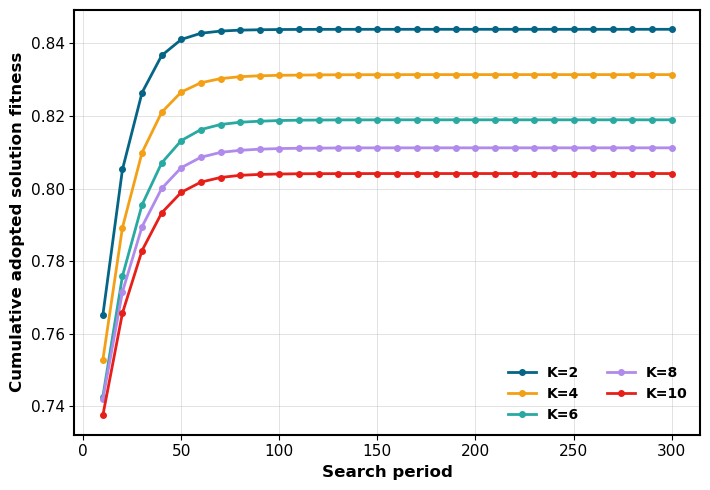

In [17]:
# Cumulative adopted solution fitness across search periods (by K).
fig, ax = plt.subplots(figsize=(7.2, 5.0))
for spine in ax.spines.values():
    spine.set_linewidth(1.5)
    spine.set_color('black')
ax.grid(alpha=0.5)
ax.tick_params(axis='both', labelsize=11)
for j, K in enumerate(K_list):
    ax.plot(trajectory_periods, trajectory_by_K[j], marker='o',
            linewidth=2.0, markersize=4, color=K_colors[j % len(K_colors)],
            label=f'K={K}')
ax.set_xlabel('Search period', fontweight='bold', fontsize=12)
ax.set_ylabel('Cumulative adopted solution fitness', fontweight='bold', fontsize=12)
ax.legend(frameon=False, ncol=2, prop={'weight': 'bold', 'size': 10})
fig.tight_layout()
# plt.savefig(figure_folder / f'Adopted_solution_fitness_by_K_across_search_periods_extent_{trajectory_visibility_extent:g}.png', dpi=300, bbox_inches='tight', transparent=True)
plt.show()

## 6. Visibility × landscape complexity

These heatmaps display the underlying saved `(extent, K)` averages without pooling across `K`. `NaN` cells remain blank, especially for adoption quality at zero visibility. They help diagnose whether an overall trend is stable or masks heterogeneous responses across landscape complexity.

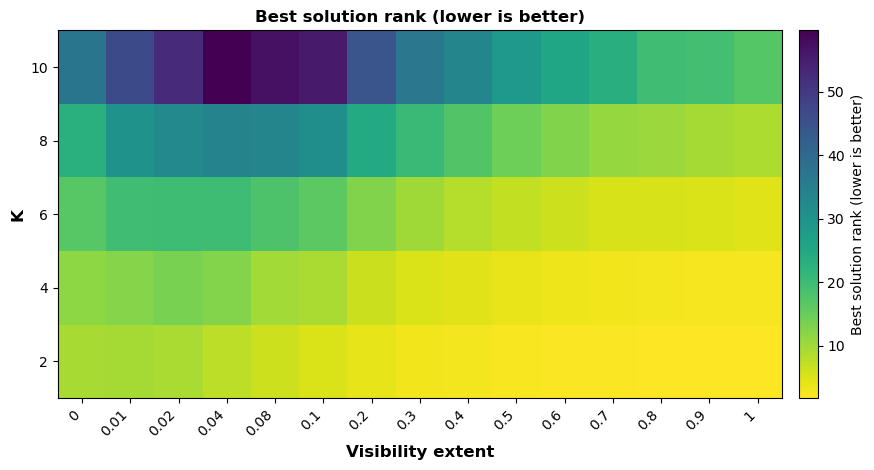

In [18]:
# Selected top-k rank across visibility extent and K.
values = np.ma.masked_invalid(data['breakthrough_rank'].T)  # (K, extent)
fig, ax = plt.subplots(figsize=(9.5, 4.8))
image = ax.imshow(values, aspect='auto', interpolation='nearest', cmap='viridis_r', origin='lower')
ax.set_xticks(np.arange(len(visibility_extent_list)))
ax.set_xticklabels([f'{extent:g}' for extent in visibility_extent_list], rotation=45, ha='right')
ax.set_yticks(np.arange(len(K_list)))
ax.set_yticklabels(K_list)
ax.set_xlabel('Visibility extent', fontweight='bold', fontsize=12)
ax.set_ylabel('K', fontweight='bold', fontsize=12)
ax.set_title(rank_axis_label, fontweight='bold', fontsize=12)
fig.colorbar(image, ax=ax, label=rank_axis_label, pad=0.02)
fig.tight_layout()
# plt.savefig(figure_folder / 'Best_solution_rank_heatmap_across_visibility_extent_and_K.png', dpi=300, bbox_inches='tight', transparent=True)
plt.show()


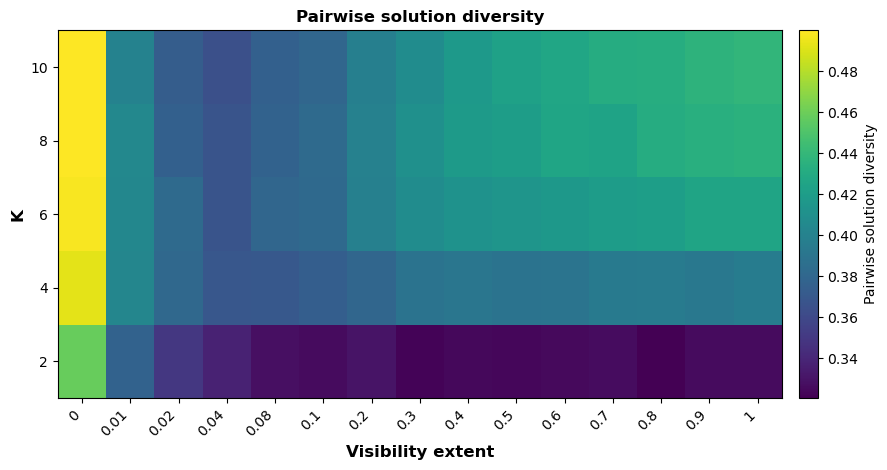

In [19]:
# Pairwise solution diversity across visibility extent and K.
values = np.ma.masked_invalid(data['pairwise_diversity'].T)  # (K, extent)
fig, ax = plt.subplots(figsize=(9.5, 4.8))
image = ax.imshow(values, aspect='auto', interpolation='nearest', cmap='viridis', origin='lower')
ax.set_xticks(np.arange(len(visibility_extent_list)))
ax.set_xticklabels([f'{extent:g}' for extent in visibility_extent_list], rotation=45, ha='right')
ax.set_yticks(np.arange(len(K_list)))
ax.set_yticklabels(K_list)
ax.set_xlabel('Visibility extent', fontweight='bold', fontsize=12)
ax.set_ylabel('K', fontweight='bold', fontsize=12)
ax.set_title('Pairwise solution diversity', fontweight='bold', fontsize=12)
fig.colorbar(image, ax=ax, label='Pairwise solution diversity', pad=0.02)
fig.tight_layout()
# plt.savefig(figure_folder / 'Pairwise_diversity_heatmap_across_visibility_extent_and_K.png', dpi=300, bbox_inches='tight', transparent=True)
plt.show()


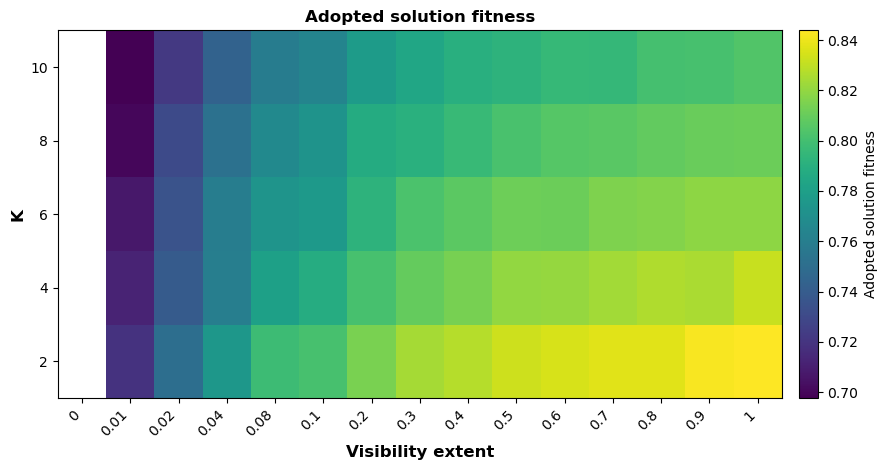

In [20]:
# Adopted solution fitness across visibility extent and K.
values = np.ma.masked_invalid(data['adopted_solution_fitness'].T)  # (K, extent)
fig, ax = plt.subplots(figsize=(9.5, 4.8))
image = ax.imshow(values, aspect='auto', interpolation='nearest', cmap='viridis', origin='lower')
ax.set_xticks(np.arange(len(visibility_extent_list)))
ax.set_xticklabels([f'{extent:g}' for extent in visibility_extent_list], rotation=45, ha='right')
ax.set_yticks(np.arange(len(K_list)))
ax.set_yticklabels(K_list)
ax.set_xlabel('Visibility extent', fontweight='bold', fontsize=12)
ax.set_ylabel('K', fontweight='bold', fontsize=12)
ax.set_title('Adopted solution fitness', fontweight='bold', fontsize=12)
fig.colorbar(image, ax=ax, label='Adopted solution fitness', pad=0.02)
fig.tight_layout()
# plt.savefig(figure_folder / 'Adopted_solution_fitness_heatmap_across_visibility_extent_and_K.png', dpi=300, bbox_inches='tight', transparent=True)
plt.show()
